# Task 1 — NER: Resume NER + Green JD corpus, fine-tuned JobBERT

> **Update (model final):** setelah notebook ini, model final diganti menjadi **JobBERT-CRF** (data & varian B yang sama, ditambah lapisan CRF). Hasilnya: S val 0.591 → 0.633, CV test exact 0.394 → 0.470, EDUCATION/EXPERIENCE paling terbantu. Lihat `task1_ner_crf.ipynb`. Angka di notebook ini adalah model softmax.

**Tujuan:** mengekstrak 4 entity yang dipakai pipeline — `SKILL`, `JOB_TITLE`, `EDUCATION`, `EXPERIENCE` — dari CV **dan** job description (JD).

**Data**
- **Resume NER** (`yashpwrr/resume-ner-training-dataset`, MIT): dokumen *rich* (punya label selain SKILL, ~820 CV setelah dedup) sebagai data utama. Dokumen yang **hanya** berlabel SKILL (83%, label otomatis & noisy, jabatan/pendidikan berlabel `O`) tidak dipakai di data utama, tapi **diuji sebagai ablasi**.
- **Green et al. 2022** (LREC, CC BY 4.0, [github](https://github.com/acp19tag/skill-extraction-dataset)): ~9.6k kalimat JD UK lintas industri, anotasi AMT + 336 kalimat test gold. Label `Skill` di sini sering berupa frasa panjang (gaya berbeda dgn CV) → cara pakainya **dibandingkan secara empiris** (bagian 6).
- **AuraATS Synthetic Resume NER 12K v2** (HF, sintetis, 20 industri): **ablasi** — apakah sedikit CV sintetis non-IT membantu.

**Keputusan desain**
| Keputusan | Pilihan |
|---|---|
| Skema | SKILL, JOB_TITLE, EDUCATION, EXPERIENCE |
| `OTHER`, `EXPERTISE`, `ACTION`, `COLLABORATION` (CV) | di-mask (`IGN`, loss = -100), bukan `O` |
| `PERSON`, `EMAIL`, `LOCATION`, `COMPANY` (CV), `Domain` (JD) | `O` |
| `CERTIFICATION` (CV) | → EDUCATION (konsisten dgn `Qualification` Green) |
| `LANGUAGE` (CV) | → SKILL (di CV lain & di Green, bahasa = skill) |
| `Skill` (JD) | **dipilih berdasarkan validasi** dari: mask semua / pakai semua / pakai yang ≤3 kata / ≤4 kata |
| Span entity > 10 kata | di-mask (semua sumber) |
| EXPERIENCE | satu label untuk ekspresi waktu pengalaman: durasi (*"5 years"*, mayoritas di JD) **dan** rentang tanggal (*"2016 to 2017"*, mayoritas di CV) |
| Augmentasi | salinan CV train dalam format ResumeAtlas (lowercase, tanpa tanda baca) supaya NER tetap jalan di data Task 2 |

**Protokol pemilihan (ditetapkan sebelum melihat hasil):** semua varian dipilih dengan skor validasi
**S = rata-rata(micro-F1 exact di CV val, micro-F1 partial di JD val)**. Gold JD val memakai label Green **asli** (Skill dihitung) dan sama untuk semua varian. Test set hanya dilaporkan, tidak dipakai memilih.

**Evaluasi test terpisah:** CV test (asli), CV test (format Atlas/lowercase), JD test (gold Green). Ditambah *proxy* recall skill pada JD dataset Task 3 (resume-ats).

Flag: `RUN_BERT`, `RUN_STAGE2` (Aura & dokumen SKILL-only), `RUN_BASELINES`, `RUN_EXPORT`, `SMOKE` (subset kecil untuk uji pipeline).

In [1]:
# Jika dijalankan di Colab / environment baru:
# %pip install -q kagglehub sklearn-crfsuite nltk "transformers>=4.40,<5" torch pandas pyarrow matplotlib seaborn datasets

In [2]:
import os, re, json, random, collections, time, warnings, urllib.request
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
ROOT = Path("..").resolve()                      # notebook berada di notebooks/
DATA, FIG, MODELS = ROOT / "data", ROOT / "figures", ROOT / "models"
for d in (DATA, FIG, MODELS): d.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

flag = lambda k, default: os.environ.get(k, default) == "1"
RUN_BERT      = flag("RUN_BERT", "1")
RUN_STAGE2    = flag("RUN_STAGE2", "1")          # ablasi: + AuraATS sintetis, + dokumen SKILL-only
RUN_BASELINES = flag("RUN_BASELINES", "1")
RUN_EXPORT    = flag("RUN_EXPORT", "1")          # prediksi entity untuk ResumeAtlas & resume-ats (butuh GPU agar cepat)
SMOKE         = flag("SMOKE", "0")               # subset kecil, hanya untuk uji pipeline

ENTITIES = ["SKILL", "JOB_TITLE", "EDUCATION", "EXPERIENCE"]
MAX_SPAN_WORDS = 10
N_AURA, N_SKILL_ONLY = 500, 1000                 # ukuran tambahan di ablasi tahap 2

def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

## 1. Load data
Semua dataset disimpan di `data/` (di-gitignore). Download otomatis jika belum ada.

In [3]:
GREEN = DATA / "green"; GREEN.mkdir(exist_ok=True)
ner_files = list(DATA.glob("kaggle/**/resume-ner-training-dataset/**/train.json"))
if not ner_files:
    os.environ["KAGGLEHUB_CACHE"] = str(DATA / "kaggle")
    import kagglehub; kagglehub.dataset_download("yashpwrr/resume-ner-training-dataset")
    ner_files = list(DATA.glob("kaggle/**/resume-ner-training-dataset/**/train.json"))
for f in ["raw_data/answers.txt", "raw_data/testset.txt", "raw_data/worker_accuracies.csv"]:
    if not (GREEN / Path(f).name).exists():
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/acp19tag/skill-extraction-dataset/main/{f}", GREEN / Path(f).name)

def load_hf(local, name):
    p = DATA / local
    if p.exists(): return pd.read_parquet(p)
    from datasets import load_dataset
    ds_ = load_dataset(name); df_ = pd.concat([ds_[k].to_pandas().assign(split=k) for k in ds_], ignore_index=True)
    df_.to_parquet(p); return df_

cv = json.load(open(ner_files[0], encoding="utf8"))
SURR = re.compile("[" + chr(0xd800) + "-" + chr(0xdfff) + "]")   # lone surrogate -> ganti 1:1 (offset anotasi tetap valid)
for x in cv: x["text"] = SURR.sub(chr(0xfffd), x["text"])
ats = load_hf("resume_ats.parquet", "0xnbk/resume-ats-score-v1-en")
ATS_JOBS = ats.text.str.split(r"\s+SEP\s+", n=1, regex=True).str[1].fillna("").drop_duplicates()
ATS_JOBS = ATS_JOBS[ATS_JOBS.str.len() > 30].tolist()
print("Resume NER:", len(cv), "dokumen | JD unik resume-ats (untuk proxy):", len(ATS_JOBS))

Resume NER: 5960 dokumen | JD unik resume-ats (untuk proxy): 320


## 2. Pilih dokumen CV *rich* + dedup
- *rich* = punya label selain SKILL (sumber DataTurks/Indeed, Resume Corpus, Doccano).
- Dokumen rich yang tidak punya `SKILL` maupun `OTHER` sama sekali dibuang: skill di sana tidak dianotasi sehingga akan jadi `O`.
- Dedup: teks ternormalisasi identik **dan** near-duplicate (300 karakter awal sama). Dari duplikat, simpan yang anotasinya terbanyak.
- Dokumen SKILL-only juga di-dedup (dipakai hanya di ablasi tahap 2).

In [4]:
labsets = [set(a[2] for a in x["annotations"]) for x in cv]
norm = lambda t: re.sub(r"\s+", " ", t.lower()).strip()

def dedup(idx):
    seen_full, seen_pre, out = set(), set(), []
    for i in sorted(idx, key=lambda i: -len(cv[i]["annotations"])):
        t = norm(cv[i]["text"])
        if t in seen_full or t[:300] in seen_pre: continue
        seen_full.add(t); seen_pre.add(t[:300]); out.append(i)
    return sorted(out)

rich = [i for i, s in enumerate(labsets) if s != {"SKILL"}]
no_skill = {i for i in rich if not ({"SKILL", "OTHER"} & labsets[i])}
cv_idx = dedup([i for i in rich if i not in no_skill])
skill_only_idx = dedup([i for i, s in enumerate(labsets) if s == {"SKILL"}])
print(f"rich: {len(rich)} | tanpa SKILL/OTHER (dibuang): {len(no_skill)} | rich setelah dedup: {len(cv_idx)}"
      f" | SKILL-only setelah dedup: {len(skill_only_idx)}")

rich: 988 | tanpa SKILL/OTHER (dibuang): 44 | rich setelah dedup: 824 | SKILL-only setelah dedup: 3274


## 3. Mapping label → skema 4 entity
Representasi internal per contoh: `tokens`, `labels` (salah satu dari ENTITIES / `O` / `IGN`), `sid` (id span, untuk membentuk BIO). `IGN` = tidak dihitung di loss & evaluasi.

Overlap span diselesaikan dengan prioritas: JOB_TITLE > EDUCATION = EXPERIENCE > SKILL > IGN.

In [5]:
CV_MAP = {"SKILL": "SKILL", "LANGUAGE": "SKILL", "DESIGNATION": "JOB_TITLE", "EDUCATION": "EDUCATION",
          "CERTIFICATION": "EDUCATION", "EXPERIENCE": "EXPERIENCE",
          "OTHER": "IGN", "EXPERTISE": "IGN", "ACTION": "IGN", "COLLABORATION": "IGN",
          "PERSON": "O", "EMAIL": "O", "LOCATION": "O", "COMPANY": "O"}
GREEN_MAP = {"Skill": "SKILL", "Occupation": "JOB_TITLE", "Qualification": "EDUCATION", "Experience": "EXPERIENCE", "Domain": "O"}
AURA_MAP = {"TITLE": "JOB_TITLE", "SKILL": "SKILL", "LANGUAGE": "SKILL", "DEGREE": "EDUCATION", "FIELD": "EDUCATION",
            "CERT": "EDUCATION", "DATE": "IGN"}   # DATE ambigu (tanggal kerja / lulus / sertifikat) -> IGN; sisanya O
PRIO = {"IGN": 1, "SKILL": 2, "EXPERIENCE": 3, "EDUCATION": 3, "JOB_TITLE": 4}

TOK = re.compile(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+|\w+(?:[.+#'-]\w+)*[+#]*|[^\w\s]")

def cap_long_spans(ex):
    """Span entity > MAX_SPAN_WORDS token -> IGN (umumnya blob section, bukan entity)."""
    size = collections.Counter(s for l, s in zip(ex["labels"], ex["sid"]) if l in ENTITIES)
    ex["labels"] = ["IGN" if l in ENTITIES and size[s] > MAX_SPAN_WORDS else l for l, s in zip(ex["labels"], ex["sid"])]
    return ex

def char_example(eid, src, text, anns, mapping):
    """anns: list (start, end, label) offset karakter."""
    toks = [(m.group(), m.start(), m.end()) for m in TOK.finditer(text)]
    st, en = np.array([a for _, a, _ in toks]), np.array([b for _, _, b in toks])
    spans = []
    for s, e, l in anns:
        L = mapping.get(l, "O")
        if L == "O": continue
        span = text[s:e]; s += len(span) - len(span.lstrip()); e -= len(span) - len(span.rstrip())   # trim whitespace
        idx = np.where((st < e) & (en > s))[0] if e > s and len(toks) else []
        if len(idx): spans.append((PRIO[L], L, idx))
    lab, pr, sid = ["O"] * len(toks), [0] * len(toks), [-1] * len(toks)
    for k, (p, L, idx) in enumerate(sorted(spans, key=lambda a: a[0])):
        for t in idx:
            if p >= pr[t]: lab[t], pr[t], sid[t] = L, p, k
    return cap_long_spans({"id": eid, "src": src, "tokens": [t for t, _, _ in toks], "labels": lab, "sid": sid})

def cv_example(i): return char_example(f"cv{i}", "cv", cv[i]["text"], cv[i]["annotations"], CV_MAP)

def bio_example(eid, src, toks, tags, mapping):
    lab, sid, k = [], [], -1
    for j, t in enumerate(tags):
        if t == "O" or "-" not in t: lab.append("O"); sid.append(-1); continue
        p, L = t.split("-", 1)
        if p == "B" or j == 0 or tags[j - 1][2:] != L: k += 1          # I- tanpa B -> span baru
        L2 = mapping.get(L, "O"); lab.append(L2); sid.append(k if L2 != "O" else -1)
    return cap_long_spans({"id": eid, "src": src, "tokens": list(toks), "labels": lab, "sid": sid})

def to_bio(ex):
    lab, sid = ex["labels"], ex["sid"]
    return [l if l in ("O", "IGN") else ("I-" if i and lab[i - 1] == l and sid[i - 1] == sid[i] else "B-") + l
            for i, l in enumerate(lab)]

cv_ex = [cv_example(i) for i in cv_idx]
print(cv_ex[0]["tokens"][:25]); print(to_bio(cv_ex[0])[:25])

['Abhishek', 'Jha', 'Application', 'Development', 'Associate', '-', 'Accenture', 'Bengaluru', ',', 'Karnataka', '-', 'Email', 'me', 'on', 'Indeed', ':', 'indeed.com', '/', 'r', '/', 'Abhishek-Jha', '/', '10e7a8cb732bc43a', '•', 'To']
['O', 'O', 'B-JOB_TITLE', 'I-JOB_TITLE', 'I-JOB_TITLE', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'O']


### Green: agregasi label AMT
`answers.txt`: token + 24 kolom label (satu per pekerja, `?` = tidak menganotasi kalimat itu). Tiap kalimat dianotasi 2 pekerja. Seperti di kode penulis (`find_tag(method='worker_indices')`), label diambil dari pekerja dengan **akurasi kualifikasi tertinggi** di antara yang menganotasi kalimat tersebut. Kalimat yang juga ada di test set dibuang.

In [6]:
acc = pd.read_csv(GREEN / "worker_accuracies.csv").set_index("worker_index").accuracy
RANK = list(acc.sort_values(ascending=False).index)

def read_conll(path):
    sents, cur = [], []
    for line in open(path, encoding="utf8", errors="replace"):
        p = line.split()
        if not p:
            if cur: sents.append(cur); cur = []
        else: cur.append(p)
    if cur: sents.append(cur)
    return sents

def aggregate(rows):
    for w in RANK:
        if all(len(r) > w + 1 and r[w + 1] != "?" for r in rows): return [r[w + 1] for r in rows]
    return None

g_test_raw = [([r[0] for r in s], [r[1] if len(r) > 1 else "O" for r in s]) for s in read_conll(GREEN / "testset.txt")]
test_keys = {" ".join(t).lower() for t, _ in g_test_raw}
g_all, n_dup = [], 0
for s in read_conll(GREEN / "answers.txt"):
    toks, tags = [r[0] for r in s], aggregate(s)
    if tags is None: continue
    if " ".join(toks).lower() in test_keys: n_dup += 1; continue
    g_all.append((toks, tags))
print(f"Green train pool: {len(g_all)} kalimat (dibuang {n_dup} yg ada di test) | Green test: {len(g_test_raw)} kalimat")

Green train pool: 9617 kalimat (dibuang 17 yg ada di test) | Green test: 336 kalimat


### Gaya label SKILL: CV vs Green
Alasan Skill Green perlu perlakuan khusus: separuh span di data AMT berupa frasa/kalimat tugas.

In [7]:
def span_words(exs, L):
    out = []
    for ex in exs:
        b = to_bio(ex)
        for i, t in enumerate(b):
            if t == "B-" + L:
                j = i + 1
                while j < len(b) and b[j] == "I-" + L: j += 1
                out.append(j - i)
    return pd.Series(out)
style = {"CV SKILL": span_words(cv_ex, "SKILL"),
         "Green Skill (AMT)": span_words([bio_example("", "", t, g, GREEN_MAP) for t, g in g_all], "SKILL"),
         "Green Skill (test gold)": span_words([bio_example("", "", t, g, GREEN_MAP) for t, g in g_test_raw], "SKILL")}
display(pd.DataFrame({k: {"n_span": len(v), "median_kata": v.median(), "1-2 kata": f"{(v <= 2).mean():.0%}",
                          ">=4 kata": f"{(v >= 4).mean():.0%}"} for k, v in style.items()}))

,CV SKILL,Green Skill (AMT),Green Skill (test gold)
n_span,10441,11547,656
median_kata,2.0,3.0,2.0
1-2 kata,72%,46%,59%
>=4 kata,14%,42%,28%


## 4. Split, augmentasi, dan varian data
- CV: split level dokumen 80/10/10 (setelah dedup).
- Green: pool AMT → 90/10 train/val; test = gold set penulis.
- Augmentasi `atlas_style`: lowercase + hapus karakter non-alfanumerik (format teks ResumeAtlas di Task 2).
- **Varian Skill Green** (hanya mengubah data *train*):
  - `mask`: semua Skill → IGN
  - `B (semua Skill)`: Skill dipakai apa adanya (tetap kena batas 10 kata)
  - `C (Skill ≤3 kata)` / `C (Skill ≤4 kata)`: Skill pendek → SKILL, yang lebih panjang → IGN

In [8]:
def atlas_style(ex):
    kept = [(re.sub(r"[^a-z0-9]", "", t.lower()), l, s) for t, l, s in zip(ex["tokens"], ex["labels"], ex["sid"])]
    kept = [k for k in kept if k[0]]
    return {**ex, "id": ex["id"] + "_lc", "tokens": [k[0] for k in kept], "labels": [k[1] for k in kept], "sid": [k[2] for k in kept]}

rng = np.random.RandomState(SEED)
perm = rng.permutation(len(cv_ex)); n_te = n_va = int(round(.1 * len(cv_ex)))
cv_test  = [cv_ex[i] for i in perm[:n_te]]
cv_val   = [cv_ex[i] for i in perm[n_te:n_te + n_va]]
cv_train = [cv_ex[i] for i in perm[n_te + n_va:]]
gperm = rng.permutation(len(g_all)); n_gv = int(round(.1 * len(g_all)))
g_val_idx, g_train_idx = gperm[:n_gv], gperm[n_gv:]
g_val  = [bio_example(f"g{i}", "jd", *g_all[i], GREEN_MAP) for i in g_val_idx]          # gold asli (Skill dihitung)
g_test = [bio_example(f"gt{i}", "jd", t, tags, GREEN_MAP) for i, (t, tags) in enumerate(g_test_raw)]
cv_test_lc = [atlas_style(e) for e in cv_test]

if SMOKE:
    cv_train, cv_val, cv_test, cv_test_lc = cv_train[:40], cv_val[:10], cv_test[:10], cv_test_lc[:10]
    g_train_idx, g_val, g_test = g_train_idx[:300], g_val[:60], g_test[:60]
    skill_only_idx, ATS_JOBS = skill_only_idx[:200], ATS_JOBS[:30]
    N_AURA, N_SKILL_ONLY = 30, 30

def green_train(mode):
    out = []
    for i in g_train_idx:
        ex = bio_example(f"g{i}", "jd", *g_all[i], GREEN_MAP)
        size = collections.Counter(s for l, s in zip(ex["labels"], ex["sid"]) if l == "SKILL")
        keep_ = (lambda n: False) if mode == "mask" else (lambda n: True) if mode == "all" else (lambda n: n <= mode)
        ex["labels"] = ["IGN" if l == "SKILL" and not keep_(size[s]) else l for l, s in zip(ex["labels"], ex["sid"])]
        out.append(ex)
    return out

GREEN_VARIANTS = {"mask": "mask", "B (semua Skill)": "all", "C (Skill ≤3 kata)": 3, "C (Skill ≤4 kata)": 4}
CV_BASE = cv_train + [atlas_style(e) for e in cv_train]
TRAINS = {name: CV_BASE + green_train(mode) for name, mode in GREEN_VARIANTS.items()}
VALS  = {"CV val": cv_val, "JD val": g_val}
TESTS = {"CV test": cv_test, "CV test (lowercase)": cv_test_lc, "JD test (gold)": g_test}

def span_counts(exs):
    c = collections.Counter()
    for e in exs:
        b = to_bio(e); c.update(t[2:] for t in b if t.startswith("B-")); c["IGN tokens"] += sum(t == "IGN" for t in b)
    return c
summary = pd.DataFrame({**{f"train: {k}": span_counts(v) for k, v in TRAINS.items()},
                        **{k: span_counts(v) for k, v in {**VALS, **TESTS}.items()}}).fillna(0).astype(int)
display(summary)

,train: mask,train: B (semua Skill),train: C (Skill ≤3 kata),train: C (Skill ≤4 kata),CV val,JD val,CV test,CV test (lowercase),JD test (gold)
JOB_TITLE,8753,8753,8753,8753,456,304,309,309,137
EDUCATION,3517,3517,3517,3517,201,47,175,175,26
EXPERIENCE,5621,5621,5621,5621,396,17,278,278,9
SKILL,16700,27039,22704,23754,1227,1208,864,864,656
IGN tokens,125365,87900,114731,110531,3590,2489,3642,3256,285


### Data tambahan untuk ablasi tahap 2
- **AuraATS** (sintetis): `N_AURA` CV acak dari split train-nya. DEGREE + "in/of" + FIELD digabung jadi satu EDUCATION (gaya CV: *"Bachelor of Science in Statistics"*). Catatan: kosakata sangat sempit (301 skill unik, 110 jabatan unik, 30 template) dan lisensi tidak dicantumkan.
- **SKILL-only**: `N_SKILL_ONLY` dokumen acak dari subset yang hanya berlabel SKILL, dipakai apa adanya.

In [9]:
def merge_degree_field(ex):
    lab, sid, tok = ex["labels"], ex["sid"], ex["tokens"]
    for i in range(1, len(lab) - 1):
        if lab[i] == "O" and tok[i].lower() in ("in", "of") and lab[i - 1] == "EDUCATION" and lab[i + 1] == "EDUCATION":
            old, new = sid[i + 1], sid[i - 1]; lab[i], sid[i] = "EDUCATION", new
            j = i + 1
            while j < len(lab) and lab[j] == "EDUCATION" and sid[j] == old: sid[j] = new; j += 1
    return ex

aura_df = load_hf("aura_synthetic_resume_ner.parquet", "sanaullah7964/AuraATS-Synthetic-Resume-NER-12K-v2")
aura_pool = aura_df[aura_df.split == "train"].sample(N_AURA, random_state=SEED)
AURA = [merge_degree_field(char_example(r.id, "aura", r.text, [(e["start"], e["end"], e["label"]) for e in r.entities], AURA_MAP))
        for r in aura_pool.itertuples()]
SKILL_ONLY = [cv_example(i) for i in np.random.RandomState(SEED).choice(skill_only_idx, min(N_SKILL_ONLY, len(skill_only_idx)), replace=False)]
display(pd.DataFrame({"AuraATS": span_counts(AURA), "SKILL-only": span_counts(SKILL_ONLY)}).fillna(0).astype(int))
for k in range(3):   # cek penggabungan DEGREE + FIELD
    print("contoh EDUCATION/JOB_TITLE Aura:", [(l, t) for t, l in zip(AURA[k]["tokens"], AURA[k]["labels"]) if l in ("EDUCATION", "JOB_TITLE")][:12])

,AuraATS,SKILL-only
JOB_TITLE,1689,0
SKILL,10420,102325
EDUCATION,1020,0
IGN tokens,4587,0


contoh EDUCATION/JOB_TITLE Aura: [('JOB_TITLE', 'Security'), ('JOB_TITLE', 'Analyst'), ('JOB_TITLE', 'Incident'), ('JOB_TITLE', 'Responder'), ('JOB_TITLE', 'Security'), ('JOB_TITLE', 'Engineer'), ('JOB_TITLE', 'GRC'), ('JOB_TITLE', 'Specialist'), ('EDUCATION', 'Bachelor'), ('EDUCATION', 'of'), ('EDUCATION', 'Engineering'), ('EDUCATION', 'in')]
contoh EDUCATION/JOB_TITLE Aura: [('JOB_TITLE', 'Platform'), ('JOB_TITLE', 'Engineer'), ('JOB_TITLE', 'Software'), ('JOB_TITLE', 'Engineer'), ('JOB_TITLE', 'Backend'), ('JOB_TITLE', 'Developer'), ('JOB_TITLE', 'API'), ('JOB_TITLE', 'Engineer'), ('JOB_TITLE', 'Backend'), ('JOB_TITLE', 'Developer'), ('EDUCATION', 'Master'), ('EDUCATION', 'of')]
contoh EDUCATION/JOB_TITLE Aura: [('JOB_TITLE', 'Inventory'), ('JOB_TITLE', 'Manager'), ('JOB_TITLE', 'Warehouse'), ('JOB_TITLE', 'Supervisor'), ('JOB_TITLE', 'Supply'), ('JOB_TITLE', 'Chain'), ('JOB_TITLE', 'Analyst'), ('JOB_TITLE', 'Procurement'), ('JOB_TITLE', 'Specialist'), ('EDUCATION', 'Master'), ('EDU

## 5. Evaluasi
- **exact**: label + batas span sama persis.
- **partial**: label sama dan token overlap (pasangan 1-1). Dipakai untuk JD karena gaya Skill berbeda.
- Prediksi yang menyentuh token `IGN` tidak dihitung sebagai false positive.
- **Proxy recall skill JD (resume-ats)**: dari 28 skill umum yang tertulis di teks JD Task 3, berapa yang ikut terekstrak sebagai SKILL. Kasar (tanpa gold), tapi langsung mengukur kebutuhan Task 3.

In [10]:
def gold_spans(ex):
    out, i, lab, sid = [], 0, ex["labels"], ex["sid"]
    while i < len(lab):
        if lab[i] in ENTITIES:
            j = i + 1
            while j < len(lab) and lab[j] == lab[i] and sid[j] == sid[i]: j += 1
            out.append((lab[i], i, j)); i = j
        else: i += 1
    return out

def bio_spans(tags):
    out, cur = [], None
    for i, t in enumerate(list(tags) + ["O"]):
        if cur and not (t.startswith("I-") and t[2:] == cur[0]): out.append((cur[0], cur[1], i)); cur = None
        if t.startswith("B-") or (t.startswith("I-") and cur is None): cur = (t[2:], i)
    return [s for s in out if s[0] in ENTITIES]

def score(exs, preds, model, dataset):
    st = {m: collections.defaultdict(lambda: [0, 0, 0]) for m in ("exact", "partial")}   # tp, fp, fn
    for ex, tags in zip(exs, preds):
        ign = {i for i, l in enumerate(ex["labels"]) if l == "IGN"}
        G = gold_spans(ex); P = [p for p in bio_spans(tags) if not ign.intersection(range(p[1], p[2]))]
        Gs, Ps = set(G), set(P)
        for g in G: st["exact"][g[0]][0 if g in Ps else 2] += 1
        for p in P:
            if p not in Gs: st["exact"][p[0]][1] += 1
        used = set()
        for g in G:
            k = next((k for k, p in enumerate(P) if k not in used and p[0] == g[0] and p[1] < g[2] and g[1] < p[2]), None)
            if k is None: st["partial"][g[0]][2] += 1
            else: used.add(k); st["partial"][g[0]][0] += 1
        for k, p in enumerate(P):
            if k not in used: st["partial"][p[0]][1] += 1
    rows = []
    for m, d in st.items():
        present = [L for L in ENTITIES if d[L][0] + d[L][2] > 0]          # hanya entity yang ada di gold
        for L in present + (["micro"] if present else []):
            tp, fp, fn = map(sum, zip(*[d[x] for x in present])) if L == "micro" else d[L]
            P_, R_ = tp / max(1, tp + fp), tp / max(1, tp + fn)
            rows.append({"model": model, "dataset": dataset, "match": m, "entity": L, "P": P_, "R": R_,
                         "F1": 2 * P_ * R_ / max(1e-9, P_ + R_), "support": tp + fn})
    return pd.DataFrame(rows)

micro = lambda df, m: df.query(f"match=='{m}' and entity=='micro'").F1.iloc[0] if len(df) else 0.0
SEL_MATCH = {"CV val": "exact", "JD val": "partial"}
def val_parts(predict_fn):
    return {f"{k} F1 ({SEL_MATCH[k]})": micro(score(v, predict_fn([e["tokens"] for e in v]), "", k), SEL_MATCH[k]) for k, v in VALS.items()}

RESULTS, PREDS = [], {}
def evaluate_all(name, predict_fn, show=True):
    for ds, exs in TESTS.items():
        PREDS[(name, ds)] = predict_fn([e["tokens"] for e in exs])
        RESULTS.append(score(exs, PREDS[(name, ds)], name, ds))
    if show:
        r = pd.concat([x for x in RESULTS if x.model.iloc[0] == name])
        display(r.pivot_table(index=["dataset", "entity"], columns="match", values="F1", sort=False).round(3))

PROXY_VOC = ["python", "java", "sql", "excel", "aws", "azure", "javascript", "react", "salesforce", "sap", "tableau", "power bi",
             "linux", "agile", "scrum", "communication", "leadership", "project management", "customer service", "accounting",
             "sales", "marketing", "jira", "git", "docker", "kubernetes", "oracle", "c#"]
def ats_skill_proxy(predict_fn):
    toks = [TOK.findall(t) for t in ATS_JOBS]; hit = miss = 0; n_sk = []
    for t, tags, txt in zip(toks, predict_fn(toks), ATS_JOBS):
        sk = [" ".join(t[s:e]).lower() for L, s, e in bio_spans(tags) if L == "SKILL"]; n_sk.append(len(sk)); joined = " | ".join(sk)
        for v in PROXY_VOC:
            pat = r"(?<![\w.#])" + re.escape(v) + r"(?![\w#])"
            if re.search(pat, txt.lower()):
                if re.search(pat, joined): hit += 1
                else: miss += 1
    n_sk = np.array(n_sk)
    return {"ATS proxy recall": hit / max(1, hit + miss), "ATS JD tanpa SKILL": (n_sk == 0).mean(), "ATS SKILL/JD": n_sk.mean()}

## 6. Fine-tuned JobBERT: perbandingan varian data
- Model: [`jjzha/jobbert-base-cased`](https://huggingface.co/jjzha/jobbert-base-cased) (BERT-base-cased + continued pretraining pada ~3,2 juta kalimat job posting; Zhang et al., NAACL 2022).
- Dokumen CV dipotong menjadi *chunk* ≤ 510 subword tanpa memotong di tengah span (bukan truncation → tidak ada teks yang hilang).
- Label hanya di subword pertama tiap kata; subword lanjutan dan token `IGN` → `-100`.
- Epoch terbaik tiap run dipilih dengan skor validasi **S** (lihat protokol di atas). Hyperparameter sama untuk semua varian.
- **Tahap 1:** 4 varian Skill Green. **Tahap 2:** pemenang tahap 1 + AuraATS, dan pemenang + dokumen SKILL-only. Model final = S tertinggi.

In [11]:
if RUN_BERT:
    import torch
    from transformers import AutoTokenizer, AutoModelForTokenClassification, get_linear_schedule_with_warmup
    DEV = "cuda" if torch.cuda.is_available() else "cpu"
    TAGS = ["O"] + [f"{p}-{L}" for L in ENTITIES for p in "BI"]; T2I = {t: i for i, t in enumerate(TAGS)}
    CFG = dict(lr=3e-5, epochs=1 if SMOKE else 3, batch=4 if DEV == "cuda" else 8, accum=2, max_len=512, warmup=.1, wd=.01)
    JOBBERT = "jjzha/jobbert-base-cased"
    print(DEV, torch.cuda.get_device_name(0) if DEV == "cuda" else "", CFG)

    def chunk_bounds(n_sub, sid=None, budget=CFG["max_len"] - 2):
        """Potong daftar kata menjadi chunk <= budget subword; utamakan batas di luar span."""
        out, start, tot = [], 0, 0
        for i, c in enumerate(n_sub):
            if tot + c > budget and i > start:
                cut = i
                if sid is not None:
                    cut = next((j for j in range(i, start, -1) if sid[j] == -1 or sid[j] != sid[j - 1]), i)
                out.append((start, cut)); start, tot = cut, sum(n_sub[cut:i])
            tot += c
        out.append((start, len(n_sub)))
        return out

    def subword_counts(tk, toks):
        if not toks: return []
        wid = tk(toks, is_split_into_words=True, add_special_tokens=False).word_ids()
        return np.bincount([w for w in wid if w is not None], minlength=len(toks)).tolist()

    def encode_examples(tk, exs):
        items = []
        for ex in exs:
            bio = to_bio(ex)
            for s, e in chunk_bounds(subword_counts(tk, ex["tokens"]), ex["sid"]):
                if s == e: continue
                enc = tk(ex["tokens"][s:e], is_split_into_words=True, truncation=True, max_length=CFG["max_len"])
                lab, prev = [], None
                for w in enc.word_ids():
                    lab.append(-100 if w is None or w == prev or bio[s + w] == "IGN" else T2I[bio[s + w]]); prev = w
                if any(l != -100 for l in lab): items.append({"input_ids": enc["input_ids"], "labels": lab})
        return items

    def make_batches(items, bs, shuffle):
        idx = list(range(len(items)))
        if shuffle: random.shuffle(idx)
        mega = [sorted(idx[i:i + bs * 50], key=lambda j: len(items[j]["input_ids"])) for i in range(0, len(idx), bs * 50)]
        bl = [m[i:i + bs] for m in mega for i in range(0, len(m), bs)]
        if shuffle: random.shuffle(bl)
        return bl

    def collate(items, pad_id):
        L = max(len(x["input_ids"]) for x in items)
        ids = torch.full((len(items), L), pad_id); att = torch.zeros((len(items), L), dtype=torch.long)
        lab = torch.full((len(items), L), -100)
        for i, x in enumerate(items):
            n = len(x["input_ids"]); ids[i, :n] = torch.tensor(x["input_ids"]); att[i, :n] = 1
            if "labels" in x: lab[i, :n] = torch.tensor(x["labels"])
        return ids, att, lab

    @torch.no_grad()
    def bert_predict(model, tk, token_lists, bs=16):
        model.eval()
        jobs = []                                                   # (doc, start, input_ids, word_ids)
        for d, toks in enumerate(token_lists):
            for s, e in chunk_bounds(subword_counts(tk, toks)):
                if s == e: continue
                enc = tk(toks[s:e], is_split_into_words=True, truncation=True, max_length=CFG["max_len"])
                jobs.append((d, s, enc["input_ids"], enc.word_ids()))
        out = [["O"] * len(t) for t in token_lists]
        for b in make_batches([{"input_ids": j[2]} for j in jobs], bs, shuffle=False):
            ids, att, _ = collate([{"input_ids": jobs[k][2]} for k in b], tk.pad_token_id)
            with torch.autocast(DEV, enabled=DEV == "cuda"):
                pred = model(input_ids=ids.to(DEV), attention_mask=att.to(DEV)).logits.argmax(-1).cpu().tolist()
            for k, p in zip(b, pred):
                d, s, _, wid = jobs[k]; prev = None
                for pos, w in enumerate(wid):
                    if w is not None and w != prev: out[d][s + w] = TAGS[p[pos]]
                    prev = w
        return out

    def train_bert(ckpt, train_set):
        torch.manual_seed(SEED); random.seed(SEED)
        tk = AutoTokenizer.from_pretrained(ckpt)
        model = AutoModelForTokenClassification.from_pretrained(ckpt, num_labels=len(TAGS), id2label=dict(enumerate(TAGS)), label2id=T2I).to(DEV)
        items = encode_examples(tk, train_set)
        n_steps = CFG["epochs"] * len(make_batches(items, CFG["batch"], False)) // CFG["accum"]
        decay = [p for n, p in model.named_parameters() if not any(x in n for x in ("bias", "LayerNorm"))]
        rest = [p for n, p in model.named_parameters() if any(x in n for x in ("bias", "LayerNorm"))]
        opt = torch.optim.AdamW([{"params": decay, "weight_decay": CFG["wd"]}, {"params": rest, "weight_decay": 0.}], lr=CFG["lr"])
        sch = get_linear_schedule_with_warmup(opt, int(CFG["warmup"] * n_steps), n_steps)
        scaler = torch.amp.GradScaler(DEV, enabled=DEV == "cuda")
        hist, best = [], (-1, None)
        print(f"  {len(items)} chunk train, {n_steps} optimizer steps")
        for ep in range(CFG["epochs"]):
            model.train(); t0, tot, nb = time.time(), 0., 0
            for bi, b in enumerate(make_batches(items, CFG["batch"], True)):
                ids, att, lab = collate([items[k] for k in b], tk.pad_token_id)
                with torch.autocast(DEV, enabled=DEV == "cuda"):
                    loss = model(input_ids=ids.to(DEV), attention_mask=att.to(DEV), labels=lab.to(DEV)).loss / CFG["accum"]
                scaler.scale(loss).backward(); tot += loss.item() * CFG["accum"]; nb += 1
                if (bi + 1) % CFG["accum"] == 0:
                    scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(opt); scaler.update(); opt.zero_grad(); sch.step()
            v = val_parts(lambda L: bert_predict(model, tk, L)); S = np.mean(list(v.values()))
            hist.append({"epoch": ep + 1, "train_loss": tot / nb, **v, "S": S})
            print(f"  epoch {ep + 1}: loss={tot / nb:.4f} " + " ".join(f"{k}={x:.3f}" for k, x in v.items()) + f" S={S:.3f} ({time.time() - t0:.0f}s)")
            if S > best[0]: best = (S, {k: t.detach().cpu().clone() for k, t in model.state_dict().items()})
        model.load_state_dict(best[1])
        return model, tk, pd.DataFrame(hist)

    HIST, COMPARE, BEST = {}, [], {"S": -1}
    def run_variant(name, train_set):
        """Latih, evaluasi (val+test+proxy), simpan hanya model dgn S tertinggi di memori."""
        import gc; gc.collect()
        if DEV == "cuda": torch.cuda.empty_cache()
        print(f"\n### {name}: {len(train_set)} contoh train")
        model, tk, HIST[name] = train_bert(JOBBERT, train_set)
        h = HIST[name].loc[HIST[name].S.idxmax()]
        pf = lambda L: bert_predict(model, tk, L)
        evaluate_all(name, pf, show=False)
        COMPARE.append({"varian": name, "best_epoch": int(h.epoch), **{k: h[k] for k in h.index if "val" in k}, "S (val)": h.S,
                        **ats_skill_proxy(pf)})
        if h.S > BEST["S"]:
            if "model" in BEST: del BEST["model"]
            BEST.update(S=h.S, name=name, model=model, tk=tk, train=train_set)
        else:
            del model

    def compare_table():
        c = pd.DataFrame(COMPARE).set_index("varian")
        r = pd.concat(RESULTS)
        cols = {"test CV micro (exact)": ("CV test", "exact", "micro"), "test CV-lc micro (exact)": ("CV test (lowercase)", "exact", "micro"),
                "test JD micro (partial)": ("JD test (gold)", "partial", "micro"), "test JD SKILL (partial)": ("JD test (gold)", "partial", "SKILL"),
                "test JD JOB_TITLE (exact)": ("JD test (gold)", "exact", "JOB_TITLE")}
        f1 = r.set_index(["model", "dataset", "match", "entity"]).F1
        for col, key in cols.items(): c[col] = [f1.get((v, *key), np.nan) for v in c.index]
        return c

cuda NVIDIA GeForce RTX 3060 Laptop GPU {'lr': 3e-05, 'epochs': 3, 'batch': 4, 'accum': 2, 'max_len': 512, 'warmup': 0.1, 'wd': 0.01}


In [12]:
if RUN_BERT:
    for name in GREEN_VARIANTS: run_variant(name, TRAINS[name])
    STAGE1_WINNER = BEST["name"]
    print("\nPemenang tahap 1 (S val tertinggi):", STAGE1_WINNER)
    display(compare_table().round(3))


### mask: 9975 contoh train


Some weights of BertForTokenClassification were not initialized from the model checkpoint at jjzha/jobbert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  11513 chunk train, 4318 optimizer steps


  epoch 1: loss=0.2641 CV val F1 (exact)=0.330 JD val F1 (partial)=0.302 S=0.316 (226s)


  epoch 2: loss=0.1038 CV val F1 (exact)=0.412 JD val F1 (partial)=0.323 S=0.367 (230s)


  epoch 3: loss=0.0742 CV val F1 (exact)=0.417 JD val F1 (partial)=0.320 S=0.368 (232s)


... (16 outputs left out)

  epoch 2: loss=0.1857 CV val F1 (exact)=0.391 JD val F1 (partial)=0.743 S=0.567 (270s)


  epoch 3: loss=0.1329 CV val F1 (exact)=0.408 JD val F1 (partial)=0.745 S=0.577 (272s)



Pemenang tahap 1 (S val tertinggi): B (semua Skill)


,best_epoch,CV val F1 (exact),JD val F1 (partial),S (val),ATS proxy recall,ATS JD tanpa SKILL,ATS SKILL/JD,test CV micro (exact),test CV-lc micro (exact),test JD micro (partial),test JD SKILL (partial),test JD JOB_TITLE (exact)
varian,,,,,,,,,,,,
mask,3,0.417,0.320,0.368,0.430,0.169,7.469,0.409,0.370,0.295,0.024,0.789
B (semua Skill),3,0.412,0.768,0.590,0.647,0.025,15.912,0.394,0.361,0.785,0.770,0.814
C (Skill ≤3 kata),3,0.414,0.730,0.572,0.600,0.025,13.041,0.388,0.361,0.756,0.723,0.863
C (Skill ≤4 kata),3,0.408,0.745,0.577,0.618,0.028,13.972,0.390,0.362,0.761,0.732,0.808


### Tahap 2: + AuraATS sintetis, + dokumen SKILL-only (di atas pemenang tahap 1)


### B (semua Skill) + AuraATS (500): 10475 contoh train


Some weights of BertForTokenClassification were not initialized from the model checkpoint at jjzha/jobbert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  12032 chunk train, 4512 optimizer steps


  epoch 1: loss=0.4733 CV val F1 (exact)=0.359 JD val F1 (partial)=0.763 S=0.561 (286s)


  epoch 2: loss=0.2600 CV val F1 (exact)=0.392 JD val F1 (partial)=0.760 S=0.576 (291s)


  epoch 3: loss=0.1920 CV val F1 (exact)=0.397 JD val F1 (partial)=0.765 S=0.581 (294s)


... (4 outputs left out)

  epoch 2: loss=0.2699 CV val F1 (exact)=0.362 JD val F1 (partial)=0.768 S=0.565 (425s)


  epoch 3: loss=0.2052 CV val F1 (exact)=0.371 JD val F1 (partial)=0.770 S=0.571 (446s)


MODEL FINAL (S val tertinggi): B (semua Skill)


,best_epoch,CV val F1 (exact),JD val F1 (partial),S (val),ATS proxy recall,ATS JD tanpa SKILL,ATS SKILL/JD,test CV micro (exact),test CV-lc micro (exact),test JD micro (partial),test JD SKILL (partial),test JD JOB_TITLE (exact)
varian,,,,,,,,,,,,
mask,3,0.417,0.320,0.368,0.430,0.169,7.469,0.409,0.370,0.295,0.024,0.789
B (semua Skill),3,0.412,0.768,0.590,0.647,0.025,15.912,0.394,0.361,0.785,0.770,0.814
C (Skill ≤3 kata),3,0.414,0.730,0.572,0.600,0.025,13.041,0.388,0.361,0.756,0.723,0.863
C (Skill ≤4 kata),3,0.408,0.745,0.577,0.618,0.028,13.972,0.390,0.362,0.761,0.732,0.808
B (semua Skill) + AuraATS (500),3,0.397,0.765,0.581,0.629,0.022,15.503,0.389,0.366,0.799,0.778,0.837
B (semua Skill) + SKILL-only (1000),3,0.371,0.770,0.571,0.858,0.009,55.356,0.366,0.361,0.791,0.770,0.871


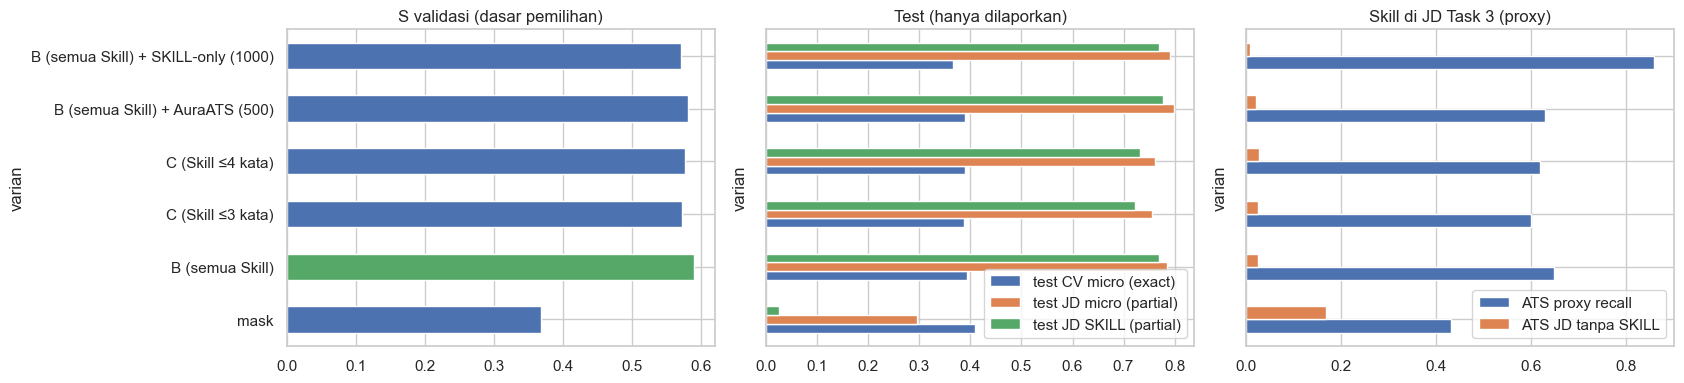

In [13]:
if RUN_BERT and RUN_STAGE2:
    base = TRAINS[STAGE1_WINNER]
    run_variant(f"{STAGE1_WINNER} + AuraATS ({len(AURA)})", base + AURA)
    run_variant(f"{STAGE1_WINNER} + SKILL-only ({len(SKILL_ONLY)})", base + SKILL_ONLY)

if RUN_BERT:
    FINAL_NAME, FINAL_TRAIN = BEST["name"], BEST["train"]
    model, tk = BEST["model"], BEST["tk"]
    if not SMOKE: model.save_pretrained(MODELS / "ner_jobbert"); tk.save_pretrained(MODELS / "ner_jobbert")
    CMP = compare_table(); CMP.to_csv(DATA / "t1_variant_comparison.csv")
    print("MODEL FINAL (S val tertinggi):", FINAL_NAME); display(CMP.round(3))
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    CMP["S (val)"].plot.barh(ax=ax[0], color=["C2" if v == FINAL_NAME else "C0" for v in CMP.index]); ax[0].set_title("S validasi (dasar pemilihan)")
    CMP[["test CV micro (exact)", "test JD micro (partial)", "test JD SKILL (partial)"]].plot.barh(ax=ax[1]); ax[1].set_title("Test (hanya dilaporkan)")
    CMP[["ATS proxy recall", "ATS JD tanpa SKILL"]].plot.barh(ax=ax[2]); ax[2].set_title("Skill di JD Task 3 (proxy)")
    for a in ax[1:]: a.set_yticklabels([])
    save("t1_variant_comparison")
else:
    FINAL_NAME, FINAL_TRAIN = "C (Skill ≤3 kata)", TRAINS["C (Skill ≤3 kata)"]

## 7. Baseline (dilatih pada data varian final)
### Rule + gazetteer (lower bound)
Gazetteer = span train yang muncul ≥2× (longest match, label mayoritas) + regex EXPERIENCE (durasi & rentang tahun).

In [14]:
YEAR = r"(?:19|20)\d\d"
DUR_UNIT = {"year", "years", "yrs", "yr", "month", "months"}
RANGE_END = re.compile(rf"^(?:{YEAR}|present|current|now|date|till)$", re.I)

def rule_experience(toks, tags):
    low = [t.lower() for t in toks]; i = 0
    while i < len(toks):
        if re.fullmatch(r"\d{1,2}", toks[i]):                          # "5 years", "5+ years"
            j = i + 1 + (i + 1 < len(toks) and toks[i + 1] == "+")
            if j < len(toks) and low[j] in DUR_UNIT:
                tags[i] = "B-EXPERIENCE"; tags[i + 1:j + 1] = ["I-EXPERIENCE"] * (j - i); i = j + 1; continue
        if re.fullmatch(YEAR, toks[i]) and i + 2 < len(toks) and low[i + 1] in {"-", "to", "–", "—"} and RANGE_END.match(toks[i + 2]):
            tags[i] = "B-EXPERIENCE"; tags[i + 1:i + 3] = ["I-EXPERIENCE"] * 2; i += 3; continue
        i += 1
    return tags

if RUN_BASELINES:
    gz = collections.defaultdict(collections.Counter)
    for ex in FINAL_TRAIN:
        if ex["id"].endswith("_lc"): continue
        for L, s, e in gold_spans(ex): gz[tuple(w.lower() for w in ex["tokens"][s:e])][L] += 1
    GAZ = {k: c.most_common(1)[0][0] for k, c in gz.items() if sum(c.values()) >= 2 and len(" ".join(k)) > 1}
    GMAX = max(map(len, GAZ))

    def rule_predict(token_lists):
        out = []
        for toks in token_lists:
            low, tags, i = [t.lower() for t in toks], ["O"] * len(toks), 0
            while i < len(toks):
                n = next((n for n in range(min(GMAX, len(toks) - i), 0, -1) if tuple(low[i:i + n]) in GAZ), 0)
                if n:
                    L = GAZ[tuple(low[i:i + n])]; tags[i:i + n] = ["B-" + L] + ["I-" + L] * (n - 1); i += n
                else: i += 1
            out.append(rule_experience(toks, tags))
        return out
    print("entri gazetteer:", len(GAZ)); evaluate_all("Rule+Gazetteer", rule_predict)

entri gazetteer: 2869


match                           exact  partial
dataset             entity                    
CV test             SKILL       0.077    0.173
                    JOB_TITLE   0.193    0.445
                    EDUCATION   0.150    0.502
                    EXPERIENCE  0.202    0.449
                    micro       0.105    0.245
CV test (lowercase) SKILL       0.076    0.172
                    JOB_TITLE   0.193    0.444
                    EDUCATION   0.130    0.502
                    EXPERIENCE  0.164    0.427
                    micro       0.100    0.242
JD test (gold)      SKILL       0.209    0.531
                    JOB_TITLE   0.231    0.706
                    EDUCATION   0.104    0.157
                    EXPERIENCE  0.190    0.667
                    micro       0.206    0.536

### CRF
Fitur: bentuk kata, kapitalisasi, affix, POS (NLTK, jika tersedia), konteks ±2. CRF tidak bisa memakai label parsial, jadi token `IGN` **dihapus** dari sekuens training (bukan dijadikan `O`). c1/c2 dipilih dengan S validasi yang sama.

In [15]:
if RUN_BASELINES:
    import sklearn_crfsuite
    try:
        import nltk
        for r_ in ["averaged_perceptron_tagger_eng", "averaged_perceptron_tagger"]: nltk.download(r_, quiet=True)
        nltk.pos_tag(["test"]); HAS_POS = True
    except Exception as ex_:
        HAS_POS = False; print("POS tagger tidak tersedia, fitur POS dilewati:", ex_)

    def shape(w): return re.sub(r"[a-z]+", "a", re.sub(r"[A-Z]+", "A", re.sub(r"\d+", "0", w)))[:6]
    def feats(toks):
        pos = [p for _, p in nltk.pos_tag(toks)] if HAS_POS and toks else ["_"] * len(toks)
        F = []
        for i, w in enumerate(toks):
            f = {"b": 1, "w": w.lower(), "up": w.isupper(), "ti": w.istitle(), "dg": w.isdigit(), "sh": shape(w),
                 "p3": w[:3].lower(), "s3": w[-3:].lower(), "pos": pos[i], "yr": bool(re.fullmatch(YEAR, w))}
            for d in (-2, -1, 1, 2):
                j = i + d
                if 0 <= j < len(toks): f.update({f"{d}:w": toks[j].lower(), f"{d}:ti": toks[j].istitle(), f"{d}:pos": pos[j]})
                else: f[f"{d}:pad"] = True
            F.append(f)
        return F

    def crf_xy(exs):
        X, Y = [], []
        for ex in exs:
            keep_, full = [i for i, l in enumerate(ex["labels"]) if l != "IGN"], to_bio(ex)
            toks, bio = [ex["tokens"][i] for i in keep_], [full[i] for i in keep_]
            if toks: X.append(feats(toks)); Y.append(bio)
        return X, Y

    t0 = time.time(); Xtr, Ytr = crf_xy(FINAL_TRAIN); print(f"fitur CRF: {len(Xtr)} sekuens, {time.time() - t0:.0f}s")
    best_crf = None
    for c1, c2 in ([(0.1, 0.1)] if SMOKE else [(0.05, 0.05), (0.1, 0.1), (0.25, 0.05)]):
        crf = sklearn_crfsuite.CRF(algorithm="lbfgs", c1=c1, c2=c2, max_iterations=5 if SMOKE else 100, all_possible_transitions=True)
        t0 = time.time(); crf.fit(Xtr, Ytr)
        v = val_parts(lambda L: crf.predict([feats(t) for t in L])); S = np.mean(list(v.values()))
        print(f"c1={c1} c2={c2}: S val={S:.3f} {v} ({time.time() - t0:.0f}s)")
        if best_crf is None or S > best_crf[0]: best_crf = (S, crf)
    crf = best_crf[1]
    evaluate_all("CRF", lambda L: crf.predict([feats(t) for t in L]))

fitur CRF: 9936 sekuens, 32s


c1=0.05 c2=0.05: S val=0.430 {'CV val F1 (exact)': np.float64(0.33324153125860645), 'JD val F1 (partial)': np.float64(0.525954525954526)} (128s)


c1=0.1 c2=0.1: S val=0.429 {'CV val F1 (exact)': np.float64(0.330999719966396), 'JD val F1 (partial)': np.float64(0.5278617710583153)} (119s)


c1=0.25 c2=0.05: S val=0.430 {'CV val F1 (exact)': np.float64(0.3393804074797656), 'JD val F1 (partial)': np.float64(0.52154984762734)} (115s)


match                           exact  partial
dataset             entity                    
CV test             SKILL       0.263    0.349
                    JOB_TITLE   0.442    0.568
                    EDUCATION   0.457    0.720
                    EXPERIENCE  0.526    0.599
                    micro       0.365    0.475
CV test (lowercase) SKILL       0.242    0.330
                    JOB_TITLE   0.405    0.530
                    EDUCATION   0.490    0.722
                    EXPERIENCE  0.471    0.568
                    micro       0.343    0.456
JD test (gold)      SKILL       0.197    0.385
                    JOB_TITLE   0.553    0.641
                    EDUCATION   0.114    0.457
                    EXPERIENCE  0.125    0.875
                    micro       0.261    0.443

## 8. Perbandingan akhir di test set

match                                    exact         partial          exact        partial  exact partial
model                          B (semua Skill) B (semua Skill) Rule+Gazetteer Rule+Gazetteer    CRF     CRF
dataset             entity                                                                                 
CV test             SKILL                0.350           0.534          0.077          0.173  0.263   0.349
                    JOB_TITLE            0.411           0.589          0.193          0.445  0.442   0.568
                    EDUCATION            0.404           0.644          0.150          0.502  0.457   0.720
                    EXPERIENCE           0.477           0.636          0.202          0.449  0.526   0.599
                    micro                0.394           0.577          0.105          0.245  0.365   0.475
CV test (lowercase) SKILL                0.302           0.486          0.076          0.172  0.242   0.330
                    JOB_TITLE            0.393           0.602          0.193          0.444  0.405   0.530
                    EDUCATION            0.353           0.645          0.130          0.502  0.490   0.722
                    EXPERIENCE           0.479           0.666          0.164          0.427  0.471   0.568
                    micro                0.361           0.563          0.100          0.242  0.343   0.456
JD test (gold)      SKILL                0.484           0.770          0.209          0.531  0.197   0.385
                    JOB_TITLE            0.814           0.862          0.231          0.706  0.553   0.641
                    EDUCATION            0.367           0.735          0.104          0.157  0.114   0.457
                    EXPERIENCE           0.381           0.857          0.190          0.667  0.125   0.875
                    micro                0.533           0.785          0.206          0.536  0.261   0.443

dataset                             CV test         CV test (lowercase)         JD test (gold)        
match                                 exact partial               exact partial          exact partial
model                                                                                                 
mask                                  0.409   0.586               0.370   0.576          0.242   0.295
B (semua Skill)                       0.394   0.577               0.361   0.563          0.533   0.785
C (Skill ≤3 kata)                     0.388   0.564               0.361   0.566          0.514   0.756
C (Skill ≤4 kata)                     0.390   0.565               0.362   0.566          0.542   0.761
B (semua Skill) + AuraATS (500)       0.389   0.558               0.366   0.561          0.530   0.799
B (semua Skill) + SKILL-only (1000)   0.366   0.548               0.361   0.559          0.542   0.791
Rule+Gazetteer                        0.105   0.245               0.100   0.242          0.206   0.536
CRF                                   0.365   0.475               0.343   0.456          0.261   0.443

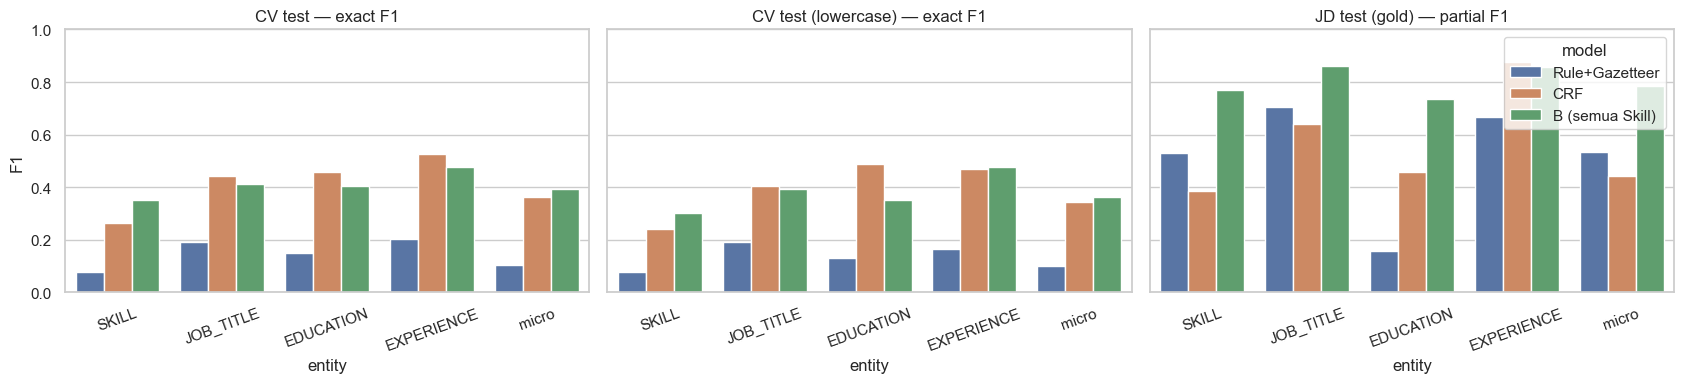

In [16]:
allr = pd.concat(RESULTS, ignore_index=True); allr.to_csv(DATA / "t1_ner_results.csv", index=False)
show_models = [m for m in ["Rule+Gazetteer", "CRF", FINAL_NAME] if m in set(allr.model)]
sub = allr[allr.model.isin(show_models)]
display(sub.pivot_table(index=["dataset", "entity"], columns=["match", "model"], values="F1", sort=False).round(3))
display(allr[allr.entity == "micro"].pivot_table(index="model", columns=["dataset", "match"], values="F1", sort=False).round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, ds in zip(axes, TESTS):
    m_ = "partial" if ds.startswith("JD") else "exact"
    d = sub[(sub.dataset == ds) & (sub.match == m_)]
    sns.barplot(data=d, x="entity", y="F1", hue="model", hue_order=show_models, ax=ax)
    ax.set_title(f"{ds} — {m_} F1"); ax.set_ylim(0, 1); ax.tick_params(axis="x", rotation=20)
    if ax is not axes[-1]: ax.get_legend().remove()
save("t1_f1_per_entity")

**Catatan membaca hasil**
- **Model final = B (semua Skill Green dipakai)**, dipilih dengan kriteria yang ditetapkan sebelum run: S val = rata-rata (F1 exact di CV val, F1 partial di JD val). S val B = 0.590, C≤4 = 0.577, C≤3 = 0.572, mask = 0.368. Test set tidak ikut dipakai untuk memilih.
- **Mask merusak sisi JD.** F1 SKILL partial di JD test cuma 0.024 dan 17% JD ATS tidak punya SKILL sama sekali. Dengan B, F1 SKILL naik ke 0.770, JD tanpa SKILL tinggal 2.5%, dan proxy recall naik dari 0.43 ke 0.65. Biayanya di CV kecil: micro exact CV test turun dari 0.409 ke 0.394.
- **Opsi C (memotong Skill panjang) tidak membantu.** Di JD, C lebih buruk daripada B (0.756/0.761 vs 0.785), dan di CV tidak lebih baik. Jadi gaya label yang berbeda tidak perlu diatasi dengan batas panjang yang di-hardcode.
- **+AuraATS (500 dokumen sintetis):** S val turun ke 0.581, karena CV val turun dari 0.412 ke 0.397. Di JD test nilainya sedikit naik (0.799), tetapi kenaikan itu terlihat di test, bukan di val, jadi tidak dipakai untuk memilih model. Aura tidak dipakai.
- **+SKILL-only (1.000 dokumen):** CV val turun paling jauh (0.412 → 0.371, S = 0.571), jadi tidak dipakai. Proxy recall ATS memang naik ke 0.86, tetapi model ini memprediksi 55 SKILL per JD (B: 16). Itu tanda over-extraction dari label lemah, bukan kemampuan yang lebih baik. Ini menjawab kenapa dokumen SKILL-only tidak dipakai: labelnya hasil string matching, sehingga model belajar menandai hampir semua kata benda teknis dan batas span di CV jadi kacau.
- **Baseline:** BERT unggul di micro semua set (CV test exact 0.394 vs CRF 0.365 vs rule 0.105; JD partial 0.785 vs 0.443 vs 0.536). Di CV, CRF masih menang untuk EDUCATION dan EXPERIENCE exact (0.457/0.526 vs 0.404/0.477). Kedua entity ini polanya sangat teratur (tanggal, gelar), dan BERT sering salah di batas span.
- **Cek seed & 4 epoch** (`task1_ner_seed_check.ipynb`, hasil di `data/t1_seed_check.csv`):
  - B tetap lebih baik dari C≤4 di **ketiga** seed (42, 13, 7). Selisih S val 0.006–0.017; rata-rata 0.590 ± 0.005 vs 0.577 ± 0.001. Seluruh selisihnya datang dari JD val (0.770 vs 0.748), sedangkan CV val setara. Jadi pemilihan B bukan kebetulan seed.
  - 4 epoch hanya menaikkan S B sebesar +0.002 (masih di bawah variasi antar-seed 0.005), dan untuk C≤4 malah turun 0.002. Karena itu model tetap dilatih 3 epoch.
  - **Peringatan:** perilaku di JD ATS (di luar domain, tanpa gold) tidak stabil antar seed. Proxy recall B berkisar 0.50–0.65 dan jumlah SKILL per JD 10–16. Angka 0.65 untuk model final (seed 42) adalah yang tertinggi dari tiga seed, jadi perkiraan yang lebih jujur adalah sekitar 0.59 ± 0.08.

## 9. Error analysis (model final)
Kategori: **boundary** (label sama, span overlap tapi batas beda), **type** (span overlap, label beda), **missed** (gold tanpa prediksi overlap), **spurious** (prediksi tanpa gold overlap).

In [17]:
def error_table(exs, preds):
    rows, examples = collections.Counter(), collections.defaultdict(list)
    for ex, tags in zip(exs, preds):
        ign = {i for i, l in enumerate(ex["labels"]) if l == "IGN"}
        G = set(gold_spans(ex)); P = {p for p in bio_spans(tags) if not ign.intersection(range(p[1], p[2]))}
        txt = lambda s: " ".join(ex["tokens"][s[1]:s[2]])
        ov = lambda a, b: a[1] < b[2] and b[1] < a[2]
        for g in G - P:
            o = [p for p in P if ov(p, g)]
            kind = "boundary" if any(p[0] == g[0] for p in o) else ("type" if o else "missed")
            rows[(g[0], kind)] += 1; examples[kind].append(f"[{g[0]}] gold='{txt(g)}' pred={[(p[0], txt(p)) for p in o]}")
        for p in P - G:
            if not any(ov(p, g) for g in G):
                rows[(p[0], "spurious")] += 1; examples["spurious"].append(f"[{p[0]}] pred='{txt(p)}'")
    return (pd.Series(rows).unstack(fill_value=0) if rows else pd.DataFrame()), examples

ERR_MODEL = FINAL_NAME if RUN_BERT else ("CRF" if RUN_BASELINES else None)
if ERR_MODEL:
    for ds in ["CV test", "JD test (gold)"]:
        t, ex_ = error_table(TESTS[ds], PREDS[(ERR_MODEL, ds)])
        print(f"\n=== {ERR_MODEL} — {ds} ==="); display(t)
        rnd = random.Random(SEED)
        for kind, lst in ex_.items(): print(f"-- {kind}:", *rnd.sample(lst, min(5, len(lst))), sep="\n   ")


=== B (semua Skill) — CV test ===


,boundary,missed,spurious,type
EDUCATION,53,26,83,12
EXPERIENCE,66,24,220,0
JOB_TITLE,75,49,223,21
SKILL,201,315,492,10


-- missed:
   [SKILL] gold='Programming' pred=[]
   [SKILL] gold='strategic planning' pred=[]
   [EDUCATION] gold='2005' pred=[]
   [SKILL] gold='sensible' pred=[]
   [JOB_TITLE] gold='HUMAN RESOURCES CONSULTANT' pred=[]
-- boundary:
   [EXPERIENCE] gold='December 2011 to June 2012' pred=[('EXPERIENCE', '2011')]
   [EXPERIENCE] gold='2020 to Present' pred=[('EXPERIENCE', 'February 2020 to Present')]
   [JOB_TITLE] gold='Officer ( HR )' pred=[('JOB_TITLE', 'Officer')]
   [SKILL] gold='of SQLWorked' pred=[('SKILL', 'SQLWorked')]
   [EXPERIENCE] gold='2008 to Current' pred=[('EXPERIENCE', '02 / 2008 to')]
-- spurious:
   [JOB_TITLE] pred='Managers'
   [SKILL] pred='Web Services'
   [EXPERIENCE] pred='Jan 2006'
   [SKILL] pred='Networking'
   [SKILL] pred='executing'
-- type:
   [SKILL] gold='Content Writer' pred=[('JOB_TITLE', 'Content Writer')]
   [JOB_TITLE] gold='C++' pred=[('SKILL', 'C++')]
   [EDUCATION] gold='2013' pred=[('EXPERIENCE', 'July 2013 – January')]
   [EDUCATION] gold='20

,boundary,missed,spurious,type
EDUCATION,9,3,3,5
EXPERIENCE,5,0,2,0
JOB_TITLE,10,21,4,3
SKILL,203,151,51,8


-- spurious:
   [JOB_TITLE] pred='Support Engineer'
   [SKILL] pred='timely'
   [SKILL] pred='looking'
   [SKILL] pred='supports'
   [SKILL] pred='the'
-- boundary:
   [SKILL] gold='ability to thrive in a challenging , fast paced environment' pred=[('SKILL', 'thrive in a challenging , fast paced environment')]
   [SKILL] gold='accuracy of operational reporting' pred=[('SKILL', 'Driving improvements in forecasting and accuracy of operational reporting')]
   [SKILL] gold='system administration configuration' pred=[('SKILL', 'maintaining data and system administration configuration')]
   [SKILL] gold='C' pred=[('SKILL', 'C Advantageous')]
   [SKILL] gold='technologies' pred=[('SKILL', 'latest technologies')]
-- missed:
   [SKILL] gold='Commercial Conferencing' pred=[]
   [SKILL] gold='ensure modeling fully reflects tax' pred=[]
   [SKILL] gold='dynamic thinking' pred=[]
   [SKILL] gold='sponsorship sales' pred=[]
   [SKILL] gold='investment process' pred=[]
-- type:
   [EDUCATION] gold='C

## 10. Output untuk Task 2 & Task 3
Kontrak output NER (dipakai Task 2 & 3):
```
{"SKILL": [...], "JOB_TITLE": [...], "EDUCATION": [...], "EXPERIENCE": [...], "experience_years": float | None}
```
String dinormalisasi: lowercase, trim, dedup (urutan dipertahankan).

`experience_years` = **draft**, perlu disepakati dengan Task 2: maksimum dari (a) durasi eksplisit "N years/months" dan (b) total rentang tahun pada span EXPERIENCE (interval digabung jika overlap).

In [18]:
def experience_years(spans, this_year=2026):
    dur, iv = [], []
    for s in spans:
        for n, unit in re.findall(r"(\d{1,2})\s*\+?\s*(years?|yrs?|months?)", s):
            dur.append(int(n) / (12 if unit.startswith("month") else 1))
        ys = [int(y) for y in re.findall(rf"\b{YEAR}\b", s)]
        if re.search(r"present|current|now|till|date", s): ys.append(this_year)
        if len(ys) >= 2 and 0 <= max(ys) - min(ys) <= 50: iv.append((min(ys), max(ys)))
    tot, cur = 0, None
    for a, b in sorted(iv):
        if cur and a <= cur[1]: cur = (cur[0], max(cur[1], b))
        else:
            if cur: tot += cur[1] - cur[0]
            cur = (a, b)
    if cur: tot += cur[1] - cur[0]
    vals = [v for v in [max(dur, default=0), tot] if v > 0]
    return float(max(vals)) if vals else None

def extract_entities(texts, model, tk):
    toks = [TOK.findall(t or "") for t in texts]
    out = []
    for t, tags in zip(toks, bert_predict(model, tk, toks)):
        d = {L: [] for L in ENTITIES}
        for L, s, e in bio_spans(tags):
            v = re.sub(r"\s+", " ", " ".join(t[s:e])).strip(" .,;:-").lower()
            if v and v not in d[L]: d[L].append(v)
        d["experience_years"] = experience_years(d["EXPERIENCE"])
        out.append(d)
    return out

if RUN_BERT:
    demo = ("John Doe\nSenior Data Analyst at Acme Corp (2018 - Present)\nData Analyst, Beta Inc 2015 - 2018\n"
            "Education: Bachelor of Science in Statistics\nSkills: Python, SQL, Tableau, stakeholder management\n"
            "Over 8 years of experience in reporting and dashboarding.")
    print(json.dumps(extract_entities([demo], model, tk)[0], indent=1))

{
 "SKILL": [
  "python",
  "sql",
  "tableau",
  "stakeholder management",
  "reporting and dashboarding"
 ],
 "JOB_TITLE": [
  "senior data analyst",
  "data analyst"
 ],
 "EDUCATION": [
  "bachelor of science in statistics"
 ],
 "EXPERIENCE": [
  "2018 - present",
  "2015 - 2018",
  "8 years of experience"
 ],
 "experience_years": 11.0
}


In [19]:
if RUN_BERT and RUN_EXPORT:
    atlas = load_hf("resume_atlas.parquet", "ahmedheakl/resume-atlas").rename(columns={"Text": "text"})
    parts = ats.text.str.split(r"\s+SEP\s+", n=1, regex=True)
    targets = {"atlas": atlas.text.fillna(""), "ats_resume": parts.str[0].drop_duplicates(), "ats_job": parts.str[1].fillna("").drop_duplicates()}
    for name, s in targets.items():
        s = s.head(20) if SMOKE else s
        t0 = time.time(); ents = extract_entities(s.tolist(), model, tk)
        df_ = pd.DataFrame(ents).assign(source_index=s.index.values, text=s.values)
        if name == "atlas": df_["Category"] = atlas.Category.loc[s.index].values
        if not SMOKE: df_.to_parquet(DATA / f"ner_pred_{name}.parquet", index=False)
        print(f"{name}: {len(df_)} teks, {time.time() - t0:.0f}s | rata-rata entity/teks:",
              {L: round(df_[L].str.len().mean(), 1) for L in ENTITIES}, "| experience_years terisi:", f"{df_.experience_years.notna().mean():.0%}")
    display(df_.head(3))

atlas: 13389 teks, 223s | rata-rata entity/teks: {'SKILL': np.float64(16.2), 'JOB_TITLE': np.float64(4.4), 'EDUCATION': np.float64(2.8), 'EXPERIENCE': np.float64(4.5)} | experience_years terisi: 53%


ats_resume: 778 teks, 27s | rata-rata entity/teks: {'SKILL': np.float64(26.9), 'JOB_TITLE': np.float64(5.9), 'EDUCATION': np.float64(3.1), 'EXPERIENCE': np.float64(5.7)} | experience_years terisi: 54%


ats_job: 320 teks, 5s | rata-rata entity/teks: {'SKILL': np.float64(15.1), 'JOB_TITLE': np.float64(2.0), 'EDUCATION': np.float64(1.5), 'EXPERIENCE': np.float64(1.4)} | experience_years terisi: 47%


,SKILL,JOB_TITLE,EDUCATION,EXPERIENCE,experience_years,source_index,text
0,"[job cost, procurement, world, data preparatio...","[jde business analystlocation, jde world homeb...",[],[10 years],10.0,0,- Share resume to shan imrsoft.com Job Title J...
1,"[software infrastructure, agile methodologies,...",[software engineering manager],"[bsms degree, computer science, engineering]",[],NaN,1,Purpose StatementThe Software Engineering Mana...
2,"[testing, execution, documentation, transforma...","[business analystlocation, product managers, b...",[bachelor s degreepmp certification],"[5 years of, experience]",5.0,2,"Title Business AnalystLocation Santa Clara, CA..."


## 11. Ringkasan & batasan
**Ringkasan**
- Model (notebook ini): `jjzha/jobbert-base-cased` + softmax, di-fine-tune pada Resume NER (824 dokumen rich + salinan gaya Atlas) dan korpus JD Green (semua label Skill). Skema 4 entity: SKILL, JOB_TITLE, EDUCATION, EXPERIENCE. Disimpan di `models/ner_jobbert`.
- Hasil test: CV micro F1 0.394 (exact) / 0.577 (partial); CV lowercase 0.361 / 0.563; JD (gold Green) 0.533 / 0.785.
- **Model final: JobBERT-CRF** (`task1_ner_crf.ipynb`, `models/ner_jobbert_crf`): CV test 0.470 (exact) / 0.604 (partial); JD 0.566 / 0.801.
- Output untuk Task 2/3 (dari model CRF) ada di `outputs/ner/` (lihat README di sana), dibuat dengan `scripts/t1_ner_predict.py --export` lalu `scripts/t1_export_outputs.py`.

**Batasan (diterima, tidak diperbaiki)**
- Skor exact SKILL di CV rendah (0.35–0.37, softmax maupun CRF). Penyebab utamanya batas span dan anotasi CV yang tidak konsisten (mis. tahun dilabeli EDUCATION). Partial F1 lebih mewakili kebutuhan matching.
- Gaya SKILL tetap campuran: di CV 1–2 kata, di JD berupa frasa panjang ("ability to thrive in a fast paced environment"). Task 3 sebaiknya mencocokkan secara semantik (embedding atau cross-encoder), bukan exact string.
- Teks ATS punya kata yang menempel (mis. "analystlocation", "degreepmp"), sehingga entity ikut menempel. Ini perlu dibersihkan di hulu (koordinasi dengan orang 3).
- Ekstraksi SKILL di JD ATS sensitif terhadap seed (proxy recall 0.50–0.65), jadi angka proxy model final kemungkinan sedikit optimistis.
- Data latih didominasi CV IT/India dari Indeed. Performa di bidang non-IT di ResumeAtlas belum terukur karena belum ada gold.

**Keputusan yang masih perlu disepakati**
- Definisi `experience_years`: saat ini diambil nilai maksimum antara durasi eksplisit dan total rentang tahun. Contoh demo memberi 11, padahal teksnya menyebut "8 years" (koordinasi dengan orang 2).
- Perlu tidaknya anotasi manual 30–50 CV non-IT untuk evaluasi.
- Model alternatif "+SKILL-only" punya recall SKILL tertinggi di JD ATS (0.86), tetapi presisinya diduga rendah. Varian ini bisa dipakai kalau orang 3 lebih butuh recall daripada presisi.